In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

df = pd.read_csv("fakenews.csv")

df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

analyzer = SentimentIntensityAnalyzer()

df["text"] = df["headline"] + " " + df["body_text"]

print(df[["label", "text"]].head())

  label                                               text
0  Real  Global economy faces recession The Prime Minis...
1  Real  Earthquake hits Chittagong, panic spreads Gove...
2  Fake  Breakthrough in Bangladesh's tech industry Loc...
3  Fake  Dengue situation worsens in the country The Pr...
4  Real  New virus outbreak sparks fear Government sour...


In [2]:
scores = df["text"].apply(
    lambda text: analyzer.polarity_scores(text)
)

sentiment_scores = pd.DataFrame(scores.tolist())

df["positive"] = sentiment_scores["pos"]
df["negative"] = sentiment_scores["neg"]
df["neutral"] = sentiment_scores["neu"]
df["compound"] = sentiment_scores["compound"]

df["sentiment_intensity"] = df["compound"].abs()

print(df[[
    "label", "positive", "negative",
    "compound", "sentiment_intensity"
]].head())

  label  positive  negative  compound  sentiment_intensity
0  Real       0.0     0.167   -0.4215               0.4215
1  Real       0.0     0.180   -0.5106               0.5106
2  Fake       0.0     0.000    0.0000               0.0000
3  Fake       0.0     0.162   -0.4767               0.4767
4  Real       0.0     0.176   -0.4939               0.4939


In [3]:
emotional_words = [
    "shocking", "outrageous", "terrifying", "horrific",
    "amazing", "disaster", " unbelievable", "evil",
    "urgent", "explosive", "devastating", "miracle",
    "disgrace", "crisis", "furious", "dangerous"
]

def count_emotional_words(text):
    words = re.findall(r"\b[a-zA-Z]+\b", str(text).lower())
    return sum(word in emotional_words for word in words)

def count_capital_words(text):
    return sum(
        1 for word in str(text).split()
        if len(word) > 1 and word.isupper()
    )

df["emotional_word_count"] = df["text"].apply(count_emotional_words)
df["exclamation_count"] = df["text"].str.count("!")
df["capital_word_count"] = df["text"].apply(count_capital_words)

df["word_count"] = df["text"].apply(
    lambda text: len(str(text).split())
)

df["emotional_word_rate"] = (
    df["emotional_word_count"] / df["word_count"].clip(lower=1) * 100
)

print(df[[
    "label", "sentiment_intensity",
    "emotional_word_count", "exclamation_count",
    "capital_word_count", "emotional_word_rate"
]].head())

  label  sentiment_intensity  emotional_word_count  exclamation_count  \
0  Real               0.4215                     0                  0   
1  Real               0.5106                     0                  0   
2  Fake               0.0000                     0                  0   
3  Fake               0.4767                     0                  0   
4  Real               0.4939                     0                  0   

   capital_word_count  emotional_word_rate  
0                   0                  0.0  
1                   0                  0.0  
2                   0                  0.0  
3                   0                  0.0  
4                   0                  0.0  


In [4]:
comparison = df.groupby("label").agg(
    average_sentiment_intensity=("sentiment_intensity", "mean"),
    average_positive_sentiment=("positive", "mean"),
    average_negative_sentiment=("negative", "mean"),
    average_emotional_words=("emotional_word_count", "mean"),
    average_exclamations=("exclamation_count", "mean"),
    average_capital_words=("capital_word_count", "mean"),
    average_emotional_word_rate=("emotional_word_rate", "mean")
).round(3)

print(comparison)

       average_sentiment_intensity  average_positive_sentiment  \
label                                                            
Fake                         0.320                       0.067   
Real                         0.333                       0.071   

       average_negative_sentiment  average_emotional_words  \
label                                                        
Fake                        0.129                      0.0   
Real                        0.127                      0.0   

       average_exclamations  average_capital_words  \
label                                                
Fake                    0.0                    0.0   
Real                    0.0                    0.0   

       average_emotional_word_rate  
label                               
Fake                           0.0  
Real                           0.0  


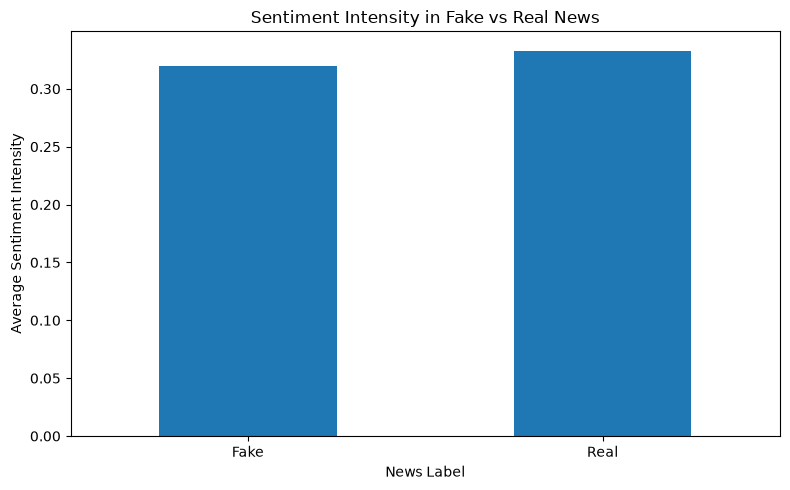

In [5]:
comparison["average_sentiment_intensity"].plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Sentiment Intensity in Fake vs Real News")
plt.xlabel("News Label")
plt.ylabel("Average Sentiment Intensity")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

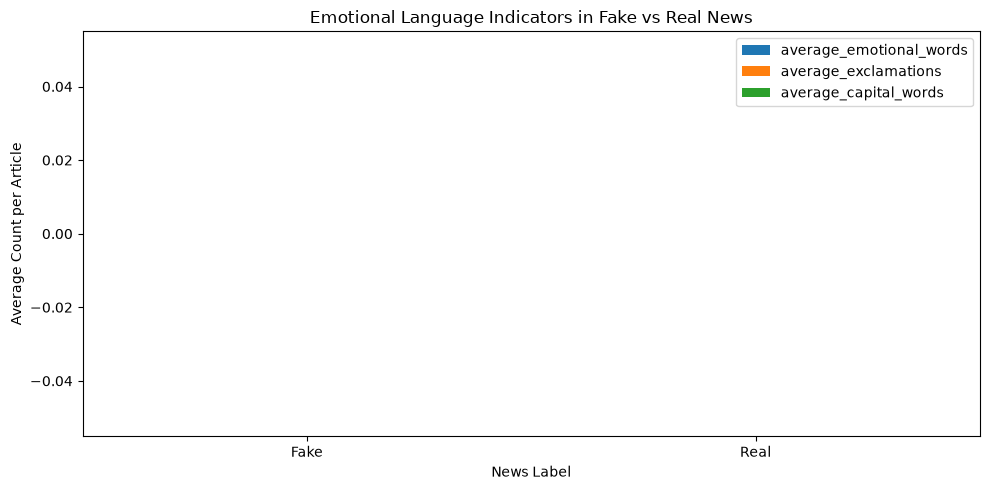

In [6]:
comparison[[
    "average_emotional_words",
    "average_exclamations",
    "average_capital_words"
]].plot(kind="bar", figsize=(10, 5))

plt.title("Emotional Language Indicators in Fake vs Real News")
plt.xlabel("News Label")
plt.ylabel("Average Count per Article")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
intensity_limit = df["sentiment_intensity"].quantile(0.75)
emotion_limit = df["emotional_word_rate"].quantile(0.75)

df["possible_exaggeration"] = (
    (df["sentiment_intensity"] >= intensity_limit) &
    (df["emotional_word_rate"] >= emotion_limit)
)

print(
    df.groupby("label")["possible_exaggeration"]
    .mean().mul(100).round(2)
    .rename("percentage_flagged")
)

flagged_articles = df[df["possible_exaggeration"]]

print(flagged_articles[[
    "news_id", "label", "headline",
    "sentiment_intensity", "emotional_word_rate"
]].head(10))

label
Fake    24.05
Real    27.95
Name: percentage_flagged, dtype: float64
    news_id label                                   headline  \
1         2  Real  Earthquake hits Chittagong, panic spreads   
5         6  Fake  Earthquake hits Chittagong, panic spreads   
7         8  Real             Global economy faces recession   
8         9  Fake  Earthquake hits Chittagong, panic spreads   
12       13  Real  Earthquake hits Chittagong, panic spreads   
18       19  Real              Bangladesh wins the World Cup   
21       22  Real  Earthquake hits Chittagong, panic spreads   
22       23  Fake  Earthquake hits Chittagong, panic spreads   
26       27  Fake  Earthquake hits Chittagong, panic spreads   
31       32  Real              Bangladesh wins the World Cup   

    sentiment_intensity  emotional_word_rate  
1                0.5106                  0.0  
5                0.7351                  0.0  
7                0.5279                  0.0  
8                0.7351         

In [8]:
df.to_csv("T34_exaggerated_sentiment_analysis.csv", index=False)
comparison.to_csv("T34_sentiment_intensity_comparison.csv")
flagged_articles.to_csv("T34_potentially_exaggerated_articles.csv", index=False)